In [1]:
from pathlib import Path
import duckdb, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)

con = duckdb.connect(str(ROOT / "warehouse.duckdb"), read_only=True)
def q(sql):
    return con.execute(sql).fetchdf()

overall = q("SELECT 100.0 * AVG(is_canceled) AS r FROM mart.bookings_enriched")["r"][0]
print(f"Overall cancellation rate: {overall:.1f}%")

Overall cancellation rate: 37.1%


In [3]:
def rate_by(col, order="category", min_bookings=200):
    return q(f"""
        SELECT {col} AS category,
               COUNT(*) AS bookings,
               ROUND(100.0 * AVG(is_canceled), 1) AS cancel_pct
        FROM mart.bookings_enriched
        GROUP BY 1
        HAVING COUNT(*) >= {min_bookings}
        ORDER BY {order}
    """)

def bar(df, title, fname):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(df["category"].astype(str), df["cancel_pct"], color="#4C78A8")
    ax.axhline(overall, color="#E45756", linestyle="--", label=f"Overall {overall:.1f}%")
    ax.set_title(title)
    ax.set_ylabel("Cancellation rate (%)")
    ax.legend()
    plt.xticks(rotation=30, ha="right")
    fig.savefig(DOCS / f"{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

,category,bookings,cancel_pct
0,0-7 days,19635,9.6
1,8-30 days,18945,27.9
2,31-90 days,29529,37.7
3,91-180 days,26420,44.7
4,181+ days,24680,57.0


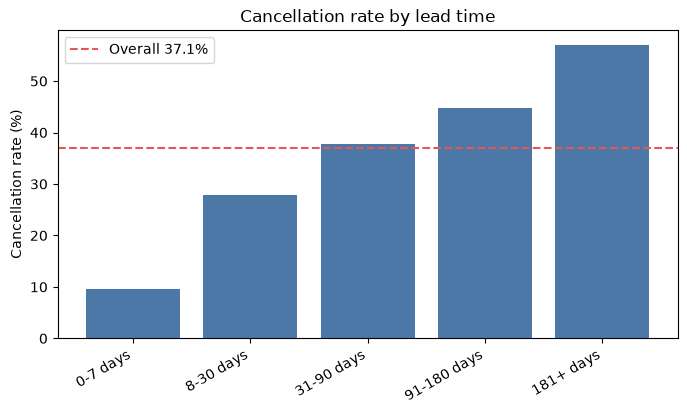

In [4]:
df = rate_by("lead_time_bucket", "MIN(lead_time)")
display(df)
bar(df, "Cancellation rate by lead time", "lead_time")

,category,bookings,cancel_pct
0,Non Refund,14587,99.4
1,No Deposit,104460,28.4


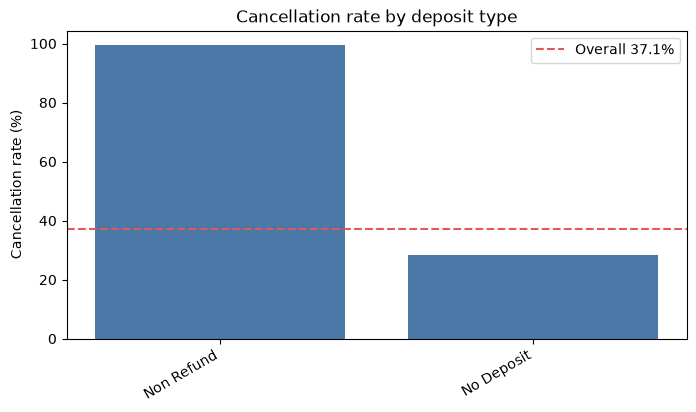

In [5]:
df = rate_by("deposit_type", "cancel_pct DESC")
display(df)
bar(df, "Cancellation rate by deposit type", "deposit_type")

,category,bookings,cancel_pct
0,0 prior,112730,33.9
1,1 prior,6048,94.4
2,2+ prior,431,52.9


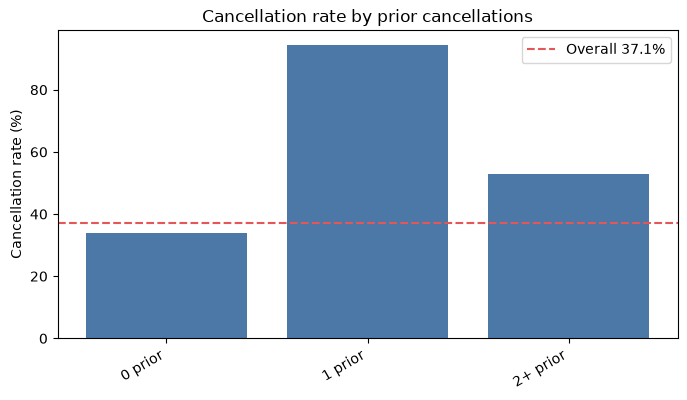

,category,bookings,cancel_pct
0,0,70200,47.8
1,1,33183,22.0
2,2,12952,22.1
3,3,2494,17.8
4,4,340,10.6


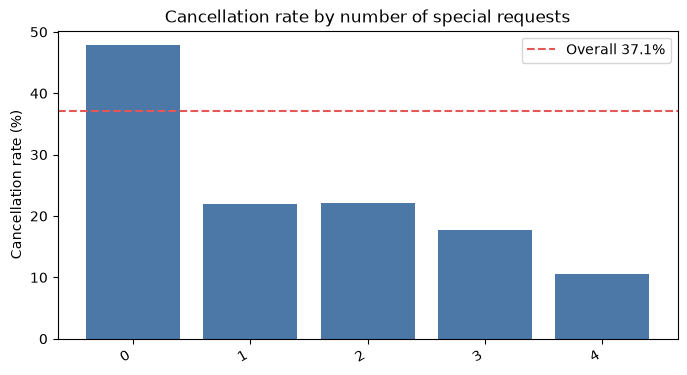

In [6]:
prior = """CASE WHEN previous_cancellations = 0 THEN '0 prior'
                WHEN previous_cancellations = 1 THEN '1 prior'
                ELSE '2+ prior' END"""
df = rate_by(prior, "category")
display(df)
bar(df, "Cancellation rate by prior cancellations", "prior_cancellations")

df = rate_by("total_of_special_requests", "category")
display(df)
bar(df, "Cancellation rate by number of special requests", "special_requests")

,category,bookings,cancel_pct
0,Groups,19790,61.1
1,Online TA,56408,36.8
2,Offline TA/TO,24182,34.3
3,Aviation,235,22.1
4,Corporate,5282,18.8
5,Direct,12582,15.4
6,Complementary,728,12.2


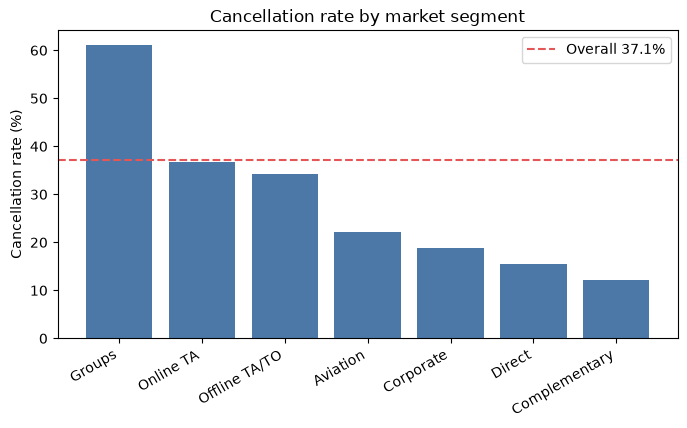

,category,bookings,cancel_pct
0,False,16280,24.7
1,True,102929,39.0


In [7]:
df = rate_by("market_segment", "cancel_pct DESC")
display(df)
bar(df, "Cancellation rate by market segment", "market_segment")

df = rate_by("has_agent", "category")
display(df)

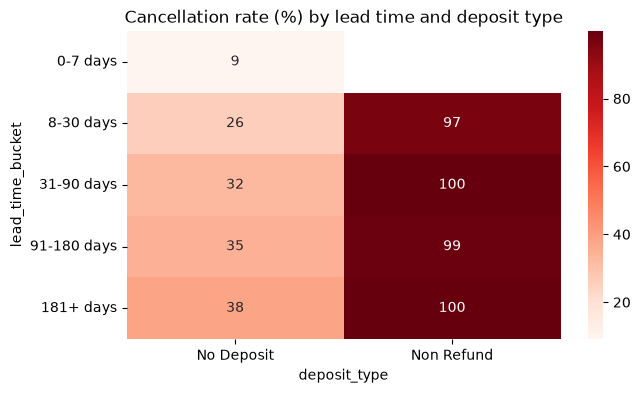

In [8]:
heat = q("""
    SELECT lead_time_bucket, deposit_type,
           100.0 * AVG(is_canceled) AS cancel_pct, COUNT(*) AS n
    FROM mart.bookings_enriched
    GROUP BY 1, 2
""")
heat = heat[heat["n"] >= 200]
order = ["0-7 days", "8-30 days", "31-90 days", "91-180 days", "181+ days"]
pivot = heat.pivot(index="lead_time_bucket", columns="deposit_type", values="cancel_pct").reindex(order)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Cancellation rate (%) by lead time and deposit type")
plt.savefig(DOCS / "lead_time_x_deposit.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
drivers = {
    "lead_time":        ("lead_time_bucket", "MIN(lead_time)"),
    "deposit_type":     ("deposit_type", "category"),
    "market_segment":   ("market_segment", "category"),
    "distribution":     ("distribution_channel", "category"),
    "customer_type":    ("customer_type", "category"),
    "hotel":            ("hotel", "category"),
    "prior_cancels":    (prior, "category"),
    "special_requests": ("total_of_special_requests", "category"),
    "booking_changes":  ("CASE WHEN booking_changes = 0 THEN '0' WHEN booking_changes = 1 THEN '1' ELSE '2+' END", "category"),
    "has_agent":        ("has_agent", "category"),
    "repeat_guest":     ("is_repeated_guest", "category"),
    "parking_requested": ("required_car_parking_spaces > 0", "category"),
}
rows = []
for name, (col, order_by) in drivers.items():
    d = rate_by(col, order_by)
    hi, lo = d["cancel_pct"].idxmax(), d["cancel_pct"].idxmin()
    rows.append((name, d["cancel_pct"].max() - d["cancel_pct"].min(),
                 d.loc[hi, "category"], d["cancel_pct"].max(),
                 d.loc[lo, "category"], d["cancel_pct"].min()))
spread = pd.DataFrame(rows, columns=["driver", "spread_pts", "highest_group", "highest_pct",
                                     "lowest_group", "lowest_pct"]).sort_values("spread_pts", ascending=False)
display(spread.round(1))

,driver,spread_pts,highest_group,highest_pct,lowest_group,lowest_pct
1,deposit_type,71.0,Non Refund,99.4,No Deposit,28.4
6,prior_cancels,60.5,1 prior,94.4,0 prior,33.9
2,market_segment,48.9,Groups,61.1,Complementary,12.2
0,lead_time,47.4,181+ days,57.0,0-7 days,9.6
11,parking_requested,39.5,False,39.5,True,0.0
7,special_requests,37.2,0,47.8,4,10.6
4,customer_type,30.7,Transient,40.8,Group,10.1
8,booking_changes,26.7,0,40.9,1,14.2
3,distribution,23.6,TA/TO,41.1,Direct,17.5
10,repeat_guest,23.1,0,37.8,1,14.7


In [11]:
cost = q("""
    SELECT COUNT(*) AS cancelled_bookings,
           ROUND(SUM(adr * total_nights)) AS room_revenue_in_cancelled_bookings
    FROM mart.bookings_enriched
    WHERE is_canceled = 1
""")
display(cost)

risk = q("""
    SELECT is_high_risk_booking, COUNT(*) AS bookings,
           ROUND(100.0 * AVG(is_canceled), 1) AS cancel_pct,
           ROUND(SUM(CASE WHEN is_canceled = 1 THEN adr * total_nights END)) AS revenue_in_cancelled
    FROM mart.bookings_enriched GROUP BY 1 ORDER BY 1
""")
display(risk)

,cancelled_bookings,room_revenue_in_cancelled_bookings
0,44199,16727237.0


,is_high_risk_booking,bookings,cancel_pct,revenue_in_cancelled
0,False,83088,37.4,10221063.0
1,True,36121,36.4,6506174.0
